<a href="https://colab.research.google.com/github/naraganibhagyasree2007/CODETECH-Car-Evaluation-System/blob/main/Car_Evaluation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the Car Evaluation dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data"

columns = [
    "buying", "maint", "doors",
    "persons", "lug_boot", "safety", "class"
]

df = pd.read_csv(url, names=columns)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

Dataset loaded successfully!
Dataset Shape: (1728, 7)

First 5 Rows:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc


In [3]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["class"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB
None

Missing Values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

Class Distribution:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [4]:
X = df.drop("class", axis=1)
y = df["class"]

encoders = {}

for column in X.columns:
    encoder = LabelEncoder()
    X[column] = encoder.fit_transform(X[column])
    encoders[column] = encoder

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y)

print("Data preprocessing completed!")
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Data preprocessing completed!
Features Shape: (1728, 6)
Target Shape: (1728,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset split completed!")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Dataset split completed!
Training Samples: 1382
Testing Samples: 346


In [6]:
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [7]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=target_encoder.classes_,
    zero_division=0
))

Model Evaluation Results
------------------------
Accuracy: 97.98 %

Classification Report:
              precision    recall  f1-score   support

         acc       0.96      0.96      0.96        77
        good       0.82      1.00      0.90        14
       unacc       1.00      1.00      1.00       242
       vgood       1.00      0.77      0.87        13

    accuracy                           0.98       346
   macro avg       0.95      0.93      0.93       346
weighted avg       0.98      0.98      0.98       346



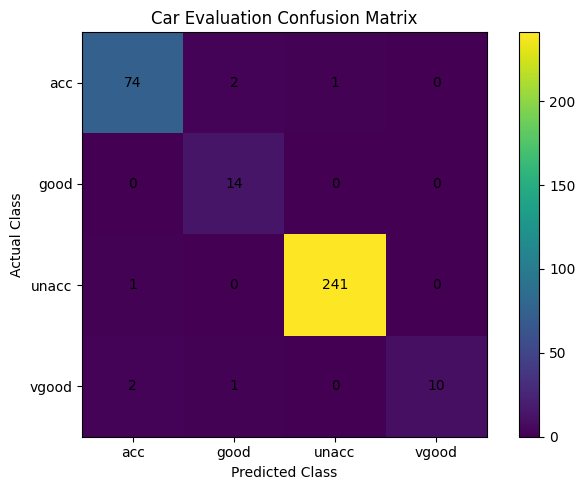

In [8]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
plt.imshow(cm)
plt.title("Car Evaluation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(range(len(target_encoder.classes_)), target_encoder.classes_)
plt.yticks(range(len(target_encoder.classes_)), target_encoder.classes_)
plt.colorbar()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

    Feature  Importance
5    safety    0.254427
1     maint    0.210630
3   persons    0.209334
0    buying    0.164287
4  lug_boot    0.097957
2     doors    0.063365


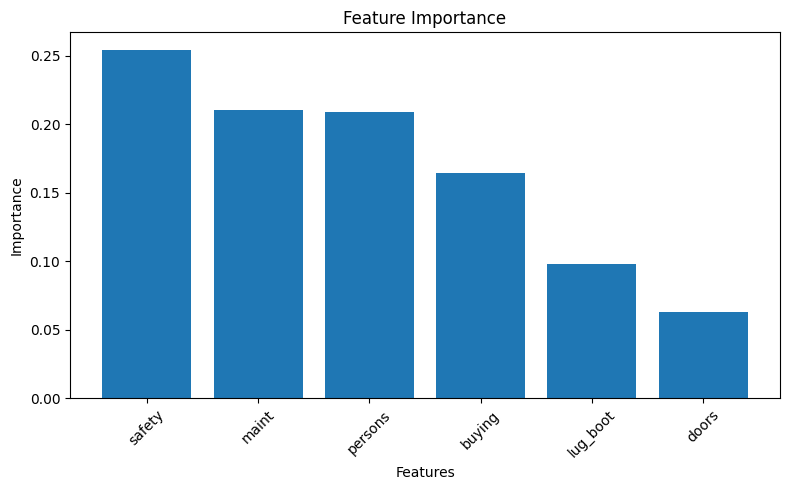

In [9]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(importance)

plt.figure(figsize=(8, 5))
plt.bar(importance["Feature"], importance["Importance"])
plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

In [10]:
new_car = pd.DataFrame([{
    "buying": "low",
    "maint": "low",
    "doors": "4",
    "persons": "4",
    "lug_boot": "big",
    "safety": "high"
}])

for column in new_car.columns:
    new_car[column] = encoders[column].transform(new_car[column])

prediction = model.predict(new_car)
predicted_class = target_encoder.inverse_transform(prediction)

print("Car Evaluation Prediction:", predicted_class[0])

Car Evaluation Prediction: vgood


In [11]:
results = pd.DataFrame({
    "Actual": target_encoder.inverse_transform(y_test),
    "Predicted": target_encoder.inverse_transform(y_pred)
})

results.to_csv("car_evaluation_results.csv", index=False)
df.to_csv("car_evaluation_dataset.csv", index=False)

import joblib

joblib.dump(model, "car_evaluation_model.pkl")
joblib.dump(encoders, "feature_encoders.pkl")
joblib.dump(target_encoder, "target_encoder.pkl")

print("All project files saved successfully!")

All project files saved successfully!


In [12]:
from google.colab import files

files.download("car_evaluation_results.csv")
files.download("car_evaluation_dataset.csv")
files.download("car_evaluation_model.pkl")
files.download("feature_encoders.pkl")
files.download("target_encoder.pkl")
files.download("confusion_matrix.png")
files.download("feature_importance.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
print("=" * 45)
print("       CAR EVALUATION SYSTEM")
print("=" * 45)

print("Dataset: UCI Car Evaluation")
print("Total Records:", len(df))
print("Total Features:", len(X.columns))
print("Algorithm: Decision Tree Classifier")
print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nCar Categories:")
for category in target_encoder.classes_:
    print("-", category)

print("\nProject Completed Successfully!")
print("=" * 45)

       CAR EVALUATION SYSTEM
Dataset: UCI Car Evaluation
Total Records: 1728
Total Features: 6
Algorithm: Decision Tree Classifier
Model Accuracy: 97.98 %

Car Categories:
- acc
- good
- unacc
- vgood

Project Completed Successfully!


In [14]:
import os
import shutil

project = "CODETECH_Task4_Car_Evaluation_System"

folders = [
    f"{project}/screenshots",
    f"{project}/output",
    f"{project}/documentation"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [15]:
# Copy notebook outputs and model files

output_files = [
    "car_evaluation_results.csv",
    "car_evaluation_dataset.csv",
    "car_evaluation_model.pkl",
    "feature_encoders.pkl",
    "target_encoder.pkl"
]

for file in output_files:
    shutil.copy(file, f"{project}/output/{file}")

# Copy generated charts

shutil.copy("confusion_matrix.png", f"{project}/screenshots/")
shutil.copy("feature_importance.png", f"{project}/screenshots/")

print("Project files organized successfully!")

Project files organized successfully!


In [16]:
requirements = """numpy
pandas
matplotlib
scikit-learn
joblib
"""

with open(f"{project}/requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [17]:
readme = """# CODETECH Task 4 - Car Evaluation System

## Intern Details
- Name: Bhagya Sree Naragani
- Intern ID: CITS9478
- Internship Duration: 12 Weeks

## Project Overview
This project predicts car acceptability using Machine Learning.
It uses the UCI Car Evaluation dataset and a Decision Tree Classifier.

## Objectives
- Load and explore the car evaluation dataset.
- Preprocess categorical data.
- Train a classification model.
- Evaluate model performance.
- Predict car acceptability.

## Technologies Used
- Python
- Google Colab
- NumPy
- Pandas
- Matplotlib
- Scikit-learn
- Joblib

## Dataset
UCI Machine Learning Repository - Car Evaluation Dataset.

## Algorithm
Decision Tree Classifier using entropy.

## Project Structure
- output/: Dataset, predictions, and saved models.
- screenshots/: Confusion matrix and feature importance charts.
- documentation/: Project documentation.
- requirements.txt: Required Python libraries.

## How to Run
1. Open the notebook in Google Colab.
2. Run all cells in order.
3. View the evaluation results and charts.

## Results
The model predicts one of four categories:
- acc
- good
- unacc
- vgood

The actual accuracy is displayed in the notebook.

## Conclusion
The project demonstrates how Machine Learning can classify
car acceptability using vehicle features.
"""

with open(f"{project}/README.md", "w") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [18]:
shutil.make_archive(project, "zip", project)

print("Final project ZIP created successfully!")
print(project + ".zip")

Final project ZIP created successfully!
CODETECH_Task4_Car_Evaluation_System.zip


In [20]:
from google.colab import files

files.download(project + ".zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>